In [ ]:
# ---- CELL 1: Mount Drive, install MediaPipe, download the pose model ----
from google.colab import drive
drive.mount('/content/drive')

!pip install -q mediapipe scipy openpyxl
!wget -q -O /content/pose_landmarker_full.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task
!ls -la /content/pose_landmarker_full.task


Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 8.8 MB/s eta 0:00:00
-rw-r--r-- 1 root root 9398198 Apr 28  2023 /content/pose_landmarker_full.task


In [ ]:
# ---- CELL 2: Settings — EDIT PATHS IF YOURS DIFFER ----
DRIVE_CLIPS_DIR = "/content/drive/MyDrive/CourtVision/clips"           # output of the cut script
SHOT_LOG_PATH   = "/content/drive/MyDrive/CourtVision/courtvision_shot_log.xlsx"
LANDMARKS_DIR   = "/content/drive/MyDrive/CourtVision/landmarks"       # raw pose output (resumable)
FEATURES_CSV    = "/content/drive/MyDrive/CourtVision/shot_features.csv"

LOCAL_CLIPS_DIR = "/content/clips_for_pose"   # local copy (fast to read)
MODEL_PATH      = "/content/pose_landmarker_full.task"

PRE_PAD = 2.0   # MUST match the value used when the clips were cut
VIS_THRESHOLD = 0.5   # landmark visibility below this is treated as "not detected"

In [ ]:
# ---- CELL 3: Copy clips from Drive to local disk (same lesson as before: local is faster) ----
import os, shutil
for label in ("2pt", "3pt"):
    os.makedirs(os.path.join(LOCAL_CLIPS_DIR, label), exist_ok=True)
    src_dir = os.path.join(DRIVE_CLIPS_DIR, label)
    for fname in sorted(os.listdir(src_dir)):
        if not fname.endswith(".mp4"):
            continue
        dst = os.path.join(LOCAL_CLIPS_DIR, label, fname)
        if not os.path.exists(dst):
            shutil.copy2(os.path.join(src_dir, fname), dst)
    print(label, "->", len(os.listdir(os.path.join(LOCAL_CLIPS_DIR, label))), "clips local")

os.makedirs(LANDMARKS_DIR, exist_ok=True)


2pt -> 63 clips local
3pt -> 53 clips local


In [ ]:

# ---- CELL 4: Helper functions ----
import time
import numpy as np
import cv2
import mediapipe as mp
import openpyxl
from scipy.signal import savgol_filter

# MediaPipe Pose landmark indices (right side = shooting side, you shoot right-handed)
NOSE, R_SHOULDER, R_ELBOW, R_WRIST, R_HIP, R_KNEE, R_ANKLE = 0, 12, 14, 16, 24, 26, 28
USED = [NOSE, R_SHOULDER, R_ELBOW, R_WRIST, R_HIP, R_KNEE, R_ANKLE]


def normalize_label(raw):
    if raw is None:
        return None
    s = str(raw).strip().lower().replace(" ", "")
    return {"2pt": "2pt", "3pt": "3pt"}.get(s)


def make_landmarker():
    opts = mp.tasks.vision.PoseLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_poses=1,
    )
    return mp.tasks.vision.PoseLandmarker.create_from_options(opts)


def extract_landmarks(video_path):
    """Returns (lms, fps): lms has shape (frames, 33, 3) = (x_px, y_px, visibility); NaN where no pose found."""
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frames = []
    with make_landmarker() as landmarker:
        idx = 0
        while True:
            ok, bgr = cap.read()
            if not ok:
                break
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            res = landmarker.detect_for_video(mp_image, int(idx * 1000 // fps))
            arr = np.full((33, 3), np.nan, dtype=np.float32)
            if res.pose_landmarks:
                for j, lm in enumerate(res.pose_landmarks[0]):
                    arr[j] = (lm.x * w, lm.y * h, lm.visibility)
            frames.append(arr)
            idx += 1
    cap.release()
    lms = np.stack(frames) if frames else np.zeros((0, 33, 3), dtype=np.float32)
    return lms, float(fps)


def interp_nans(a):
    """Linear-interpolate NaNs along time for each column of a (T, k) array."""
    a = a.copy()
    t = np.arange(len(a))
    for c in range(a.shape[1]):
        good = ~np.isnan(a[:, c])
        if good.sum() >= 2:
            a[:, c] = np.interp(t, t[good], a[good, c])
    return a


def smooth(a, win=7):
    n = len(a)
    win = min(win, n if n % 2 == 1 else n - 1)
    if win < 5:
        return a
    return savgol_filter(a, window_length=win, polyorder=2, axis=0)


def angle_at(a, b, c):
    """Angle in degrees at point b formed by a-b-c. Inputs shape (T, 2)."""
    v1, v2 = a - b, c - b
    cosang = (v1 * v2).sum(1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1) + 1e-9)
    return np.degrees(np.arccos(np.clip(cosang, -1, 1)))


def lean_from_vertical(p_from, p_to):
    """Signed angle (deg) of the vector p_from->p_to relative to straight up. y must already be 'up'.
    0 = straight up, positive = leaning toward the direction the shooter faces."""
    d = p_to - p_from
    return np.degrees(np.arctan2(d[:, 0], d[:, 1]))


FEATURE_NAMES = [
    "elbow_angle", "knee_angle", "hip_angle", "shoulder_angle",
    "wrist_above_shoulder", "wrist_above_head", "forearm_lean", "trunk_lean",
    "min_knee_pre", "knee_extension", "t_min_knee_to_release",
    "jump_at_release", "jump_peak", "max_knee_ext_speed", "max_wrist_rise_speed",
]


def compute_features(lms, fps, release_time):
    """lms: (T,33,3). Returns (feature dict, coverage)."""
    T = len(lms)
    feats = {k: np.nan for k in FEATURE_NAMES}
    if T < 10:
        return feats, 0.0

    xy = lms[:, USED, :2].copy()           # (T, 7, 2)
    vis = lms[:, USED, 2]                  # (T, 7)
    xy[vis < VIS_THRESHOLD] = np.nan       # low-confidence -> missing (also covers NaN)
    # coverage = fraction of frames where every joint we use was detected
    coverage = float(np.mean(~np.isnan(xy).any(axis=(1, 2))))
    if coverage < 0.3:
        return feats, coverage

    # interpolate gaps, smooth, then convert to "y up" so higher = bigger y
    flat = interp_nans(xy.reshape(T, -1))
    flat = smooth(flat)
    pts = flat.reshape(T, 7, 2)
    pts[:, :, 1] *= -1                     # y up
    nose, sh, el, wr, hip, kn, an = [pts[:, i, :] for i in range(7)]

    r = int(np.clip(round(release_time * fps), 0, T - 1))

    # make the shooter always face +x (so signed leans mean the same thing in every clip)
    lo, hi = max(0, r - 3), min(T, r + 4)
    facing = np.sign(np.nanmedian(wr[lo:hi, 0] - hip[lo:hi, 0]))
    if facing < 0:
        for arr in (nose, sh, el, wr, hip, kn, an):
            arr[:, 0] *= -1

    torso = float(np.median(np.linalg.norm(sh - hip, axis=1))) + 1e-9   # body-size unit

    elbow = angle_at(sh, el, wr)
    knee = angle_at(hip, kn, an)
    hip_ang = angle_at(sh, hip, kn)
    sh_ang = angle_at(hip, sh, el)

    feats["elbow_angle"] = elbow[r]
    feats["knee_angle"] = knee[r]
    feats["hip_angle"] = hip_ang[r]
    feats["shoulder_angle"] = sh_ang[r]
    feats["wrist_above_shoulder"] = (wr[r, 1] - sh[r, 1]) / torso
    feats["wrist_above_head"] = (wr[r, 1] - nose[r, 1]) / torso
    feats["forearm_lean"] = lean_from_vertical(el, wr)[r]
    feats["trunk_lean"] = lean_from_vertical(hip, sh)[r]

    # --- window features ---
    pre_start = max(0, r - int(1.5 * fps))
    seg = knee[pre_start:r + 1]
    j = int(np.argmin(seg))
    feats["min_knee_pre"] = float(seg[j])
    feats["knee_extension"] = float(knee[r] - seg[j])
    feats["t_min_knee_to_release"] = float((r - (pre_start + j)) / fps)

    # jump height proxy: hip height above standing baseline, in torso-lengths.
    # baseline = median hip height in frames away from the jump.
    away = np.ones(T, dtype=bool)
    away[max(0, r - int(0.6 * fps)):min(T, r + int(0.6 * fps) + 1)] = False
    base = np.median(hip[away, 1]) if away.sum() >= 5 else np.percentile(hip[:, 1], 20)
    jump = (hip[:, 1] - base) / torso
    w0, w1 = max(0, r - int(0.5 * fps)), min(T, r + int(0.5 * fps) + 1)
    feats["jump_at_release"] = float(jump[r])
    feats["jump_peak"] = float(jump[w0:w1].max())

    sp0 = max(0, r - int(0.8 * fps))
    knee_speed = np.gradient(knee) * fps
    wrist_speed = np.gradient(wr[:, 1]) * fps / torso
    feats["max_knee_ext_speed"] = float(knee_speed[sp0:r + 1].max())
    feats["max_wrist_rise_speed"] = float(wrist_speed[sp0:r + 1].max())

    return feats, coverage


In [ ]:

# ---- CELL 5: Read the shot log, build the list of clips ----
wb = openpyxl.load_workbook(SHOT_LOG_PATH, data_only=True)
ws = wb.active
shots = []
for video, shot_number, ts, label in ws.iter_rows(min_row=3, max_row=ws.max_row, values_only=True):
    if video is None or not isinstance(ts, (int, float)):
        continue
    lab = normalize_label(label)
    if lab is None:
        continue
    stem = os.path.splitext(video)[0]
    start = max(0.0, float(ts) - PRE_PAD)
    shots.append({
        "clip": f"{stem}_shot{shot_number}_{lab}",
        "video": video, "shot_number": shot_number, "label": lab,
        "release_time": float(ts) - start,    # seconds into the clip
    })
print(len(shots), "shots to process")


116 shots to process


In [ ]:
# ---- CELL 6: Run MediaPipe on every clip (slow part — resumable) ----
done = failed = skipped = 0
t_start = time.time()
for i, s in enumerate(shots, start=1):
    out_path = os.path.join(LANDMARKS_DIR, s["clip"] + ".npz")
    if os.path.exists(out_path):
        skipped += 1
        continue
    clip_path = os.path.join(LOCAL_CLIPS_DIR, s["label"], s["clip"] + ".mp4")
    if not os.path.exists(clip_path):
        print(f"[{i}/{len(shots)}] MISSING clip {s['clip']}", flush=True)
        failed += 1
        continue
    t0 = time.time()
    try:
        lms, fps = extract_landmarks(clip_path)
        np.savez_compressed(out_path, lms=lms, fps=fps)
        det = float(np.mean(~np.isnan(lms[:, R_WRIST, 0]))) if len(lms) else 0.0
        print(f"[{i}/{len(shots)}] {s['clip']}: {len(lms)} frames, pose found in {det:.0%}, {time.time()-t0:.1f}s", flush=True)
        done += 1
    except Exception as e:
        print(f"[{i}/{len(shots)}] FAILED {s['clip']}: {e}", flush=True)
        failed += 1
print(f"\nDone {done}, already had {skipped}, failed {failed}, total {(time.time()-t_start)/60:.1f} min")


[1/116] IMG_3128_shot1_2pt: 120 frames, pose found in 100%, 7.2s
[2/116] IMG_3128_shot2_2pt: 120 frames, pose found in 100%, 5.4s
[3/116] IMG_3128_shot3_2pt: 120 frames, pose found in 88%, 5.1s
[4/116] IMG_3127_shot1_2pt: 120 frames, pose found in 100%, 6.1s
[5/116] IMG_3127_shot2_2pt: 120 frames, pose found in 100%, 5.6s
[6/116] IMG_3127_shot3_2pt: 120 frames, pose found in 100%, 4.7s
[7/116] IMG_3127_shot4_2pt: 120 frames, pose found in 88%, 6.8s
[8/116] IMG_3126_shot1_2pt: 120 frames, pose found in 100%, 4.7s
[9/116] IMG_3126_shot2_2pt: 120 frames, pose found in 100%, 4.5s
[10/116] IMG_3126_shot3_2pt: 120 frames, pose found in 100%, 6.9s
[11/116] IMG_3126_shot4_2pt: 120 frames, pose found in 100%, 4.8s
[12/116] IMG_3126_shot5_2pt: 120 frames, pose found in 95%, 4.8s
[13/116] IMG_3124_shot1_2pt: 120 frames, pose found in 100%, 6.5s
[14/116] IMG_3124_shot2_2pt: 120 frames, pose found in 100%, 4.7s
[15/116] IMG_3124_shot3_2pt: 120 frames, pose found in 100%, 5.7s
[16/116] IMG_3124_shot

In [ ]:
# ---- CELL 7 (v2): Re-anchor release to the wrist peak, then compute features ----
import pandas as pd

SEARCH_BEFORE = 0.3   # s before logged time to search
SEARCH_AFTER  = 1.0   # s after logged time to search
PEAK_TO_RELEASE = 0.1 # release ~0.1s before wrist peak

def find_release(lms, fps, logged_time):
    """Returns (new_release_time, peak_offset, edge_flag). Falls back to logged time if wrist missing."""
    T = len(lms)
    xy = lms[:, [R_WRIST], :2].copy().reshape(T, 2)
    xy[lms[:, R_WRIST, 2] < VIS_THRESHOLD] = np.nan
    if np.isnan(xy[:, 1]).all():
        return logged_time, np.nan, True
    wy = -smooth(interp_nans(xy))[:, 1]                    # y up
    r = int(round(logged_time * fps))
    a = max(0, r - int(SEARCH_BEFORE * fps))
    b = min(T, r + int(SEARCH_AFTER * fps) + 1)
    k = a + int(np.argmax(wy[a:b]))
    edge = (k >= b - 2) or (k <= a + 1)                    # peak at edge of window = unreliable
    new_rel = max(0.0, k / fps - PEAK_TO_RELEASE)
    return new_rel, (k / fps - logged_time), bool(edge)

rows = []
for s in shots:
    path = os.path.join(LANDMARKS_DIR, s["clip"] + ".npz")
    if not os.path.exists(path):
        continue
    d = np.load(path)
    lms, fps = d["lms"], float(d["fps"])
    new_rel, peak_off, edge = find_release(lms, fps, s["release_time"])
    feats, cov = compute_features(lms, fps, new_rel)
    rows.append({
        "clip": s["clip"], "video": s["video"], "shot_number": s["shot_number"],
        "label": s["label"], "is_3pt": int(s["label"] == "3pt"),
        "logged_time": round(s["release_time"], 2), "release_time": round(new_rel, 2),
        "peak_offset": round(peak_off, 2) if peak_off == peak_off else np.nan,
        "edge_flag": int(edge), "coverage": round(cov, 2),
        **feats,
    })

df = pd.DataFrame(rows)

DROP_CLIPS = ["IMG_0856_shot5_2pt"]
df = df[~df["clip"].isin(DROP_CLIPS)].reset_index(drop=True)

df.to_csv(FEATURES_CSV, index=False)
print("Saved", len(df), "rows ->", FEATURES_CSV)
print("\nRows per class:\n", df["label"].value_counts().to_string())

print("\nEdge-flagged clips (peak at search-window edge, check these):")
e = df[df["edge_flag"] == 1]
print(e[["clip", "logged_time", "release_time", "peak_offset"]].to_string(index=False) if len(e) else "none")

print("\nLow-coverage clips (<70%):")
lc = df[df["coverage"] < 0.7]
print(lc[["clip", "coverage"]].to_string(index=False) if len(lc) else "none")

print("\nMissing feature values:", int(df[FEATURE_NAMES].isna().sum().sum()))
print("\nFeature means by class:")
print(df.groupby("label")[FEATURE_NAMES].mean().round(2).T.to_string())

Saved 115 rows -> /content/drive/MyDrive/CourtVision/shot_features.csv

Rows per class:
 label
2pt    62
3pt    53

Edge-flagged clips (peak at search-window edge, check these):
              clip  logged_time  release_time  peak_offset
IMG_3128_shot2_2pt          2.0           2.9          1.0
IMG_3121_shot1_2pt          2.0           2.9          1.0
IMG_3119_shot5_2pt          2.0           2.9          1.0
IMG_3118_shot3_2pt          2.0           2.9          1.0
IMG_0869_shot3_3pt          2.0           2.9          1.0
IMG_0869_shot4_3pt          2.0           2.9          1.0

Low-coverage clips (<70%):
              clip  coverage
IMG_3121_shot1_2pt      0.47
IMG_3121_shot3_2pt      0.64
IMG_3119_shot3_2pt      0.68
IMG_3119_shot4_2pt      0.67
IMG_3118_shot1_2pt      0.69
IMG_3118_shot2_2pt      0.49
IMG_0868_shot1_3pt      0.57

Missing feature values: 0

Feature means by class:
label                         2pt         3pt
elbow_angle            119.559998  128.970001
knee_

In [ ]:
# # ---- CELL 8: Release-timing check ----
# rows = []
# for s in shots:
#     p = os.path.join(LANDMARKS_DIR, s["clip"] + ".npz")
#     if not os.path.exists(p):
#         continue
#     d = np.load(p); lms, fps = d["lms"], float(d["fps"])
#     xy = lms[:, [R_WRIST, R_HIP], :2].copy()
#     xy[lms[:, [R_WRIST, R_HIP], 2] < VIS_THRESHOLD] = np.nan
#     flat = smooth(interp_nans(xy.reshape(len(lms), -1)))
#     wy, hy = -flat[:, 1], -flat[:, 3]          # y up
#     r = int(round(s["release_time"] * fps))
#     a, b = max(0, r - int(fps)), min(len(lms), r + int(fps) + 1)
#     rows.append({"clip": s["clip"], "label": s["label"],
#                  "wrist_peak_offset": (a + np.argmax(wy[a:b]) - r) / fps,
#                  "hip_peak_offset":   (a + np.argmax(hy[a:b]) - r) / fps})
# t = pd.DataFrame(rows)
# print(t.groupby("label")[["wrist_peak_offset", "hip_peak_offset"]]
#         .agg(["median", "std", "min", "max"]).round(2).T.to_string())

label                      2pt   3pt
wrist_peak_offset median  0.42  0.65
                  std     0.31  0.29
                  min    -0.03 -0.08
                  max     1.00  1.00
hip_peak_offset   median  0.50  0.68
                  std     0.52  0.36
                  min    -1.00 -0.98
                  max     1.00  1.00


In [ ]:
# # ---- CELL 9: How many shots hit the window edge? ----
# edge = t[(t["wrist_peak_offset"] >= 0.95) | (t["wrist_peak_offset"] <= -0.95)]
# print(len(edge), "of", len(t), "at window edge")
# print(t.groupby("label")["wrist_peak_offset"].describe().round(2).to_string())
# print(t.sort_values("wrist_peak_offset", ascending=False).head(6)[["clip", "wrist_peak_offset"]].to_string(index=False))

8 of 116 at window edge
       count  mean   std   min   25%   50%   75%  max
label                                                
2pt     63.0  0.47  0.31 -0.03  0.20  0.42  0.71  1.0
3pt     53.0  0.58  0.29 -0.08  0.35  0.65  0.82  1.0
              clip  wrist_peak_offset
IMG_3128_shot2_2pt                1.0
IMG_3121_shot1_2pt                1.0
IMG_3118_shot3_2pt                1.0
IMG_3119_shot5_2pt                1.0
IMG_0869_shot3_3pt                1.0
IMG_0869_shot4_3pt                1.0


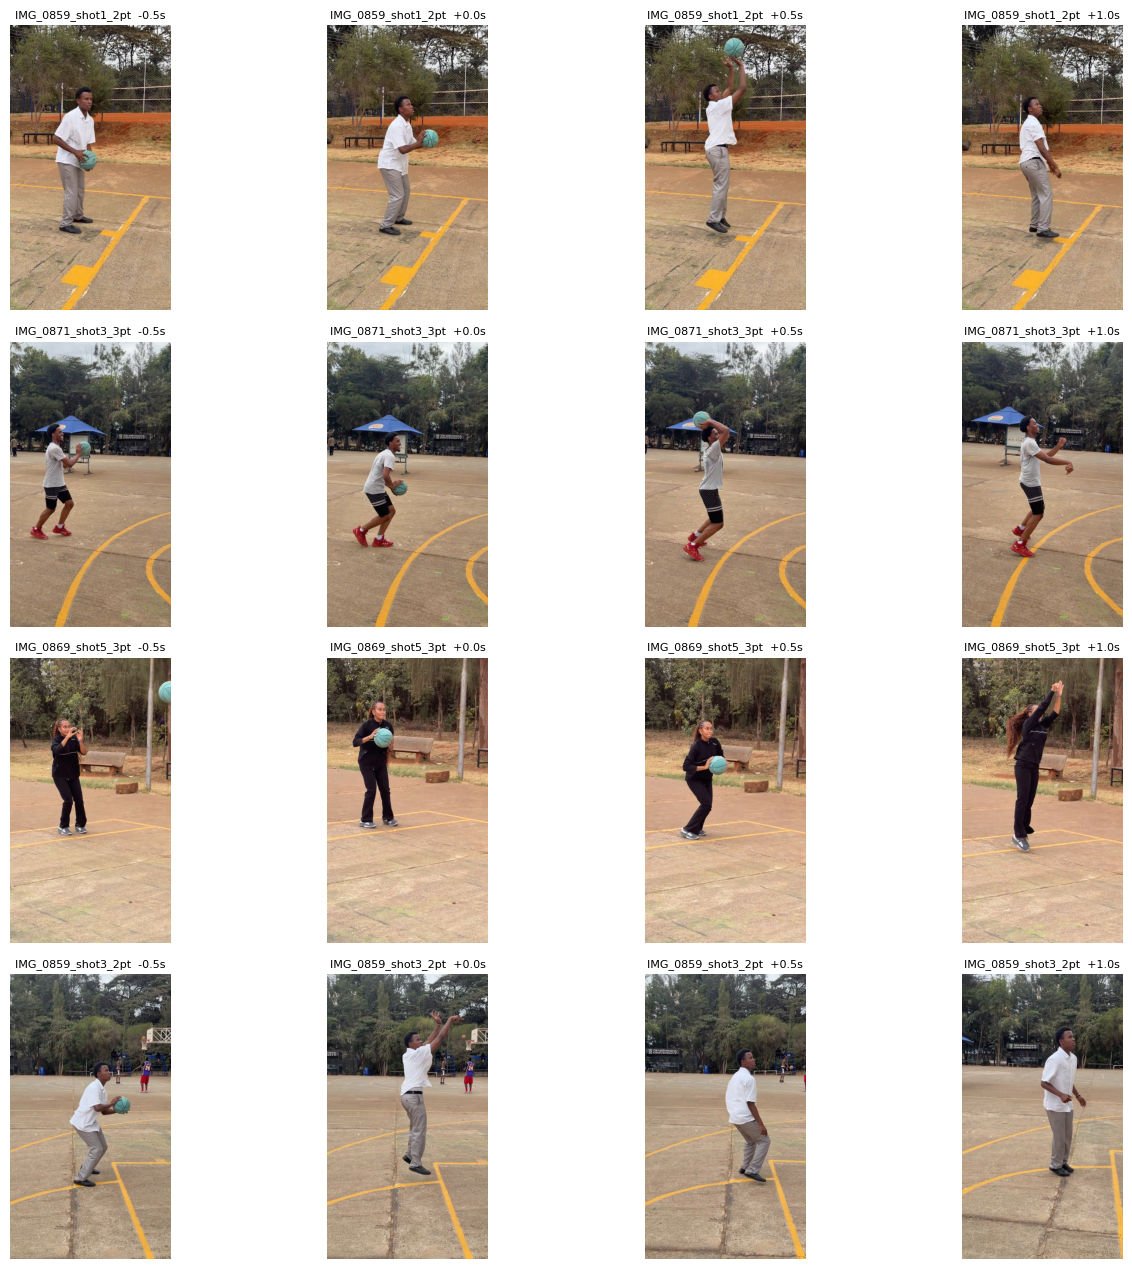

In [ ]:
# # ---- CELL 10: Eyeball the release frame ----
# import matplotlib.pyplot as plt
# pick = t.sample(4, random_state=1)["clip"].tolist()
# offs = [-0.5, 0, 0.5, 1.0]
# fig, axes = plt.subplots(len(pick), len(offs), figsize=(14, 3.2 * len(pick)))
# for i, name in enumerate(pick):
#     s = next(x for x in shots if x["clip"] == name)
#     cap = cv2.VideoCapture(os.path.join(LOCAL_CLIPS_DIR, s["label"], name + ".mp4"))
#     for j, o in enumerate(offs):
#         cap.set(cv2.CAP_PROP_POS_MSEC, (s["release_time"] + o) * 1000)
#         ok, f = cap.read()
#         ax = axes[i, j]; ax.axis("off")
#         if ok:
#             ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
#         ax.set_title(f"{name[:18]}  {o:+.1f}s", fontsize=8)
#     cap.release()
# plt.tight_layout(); plt.show()

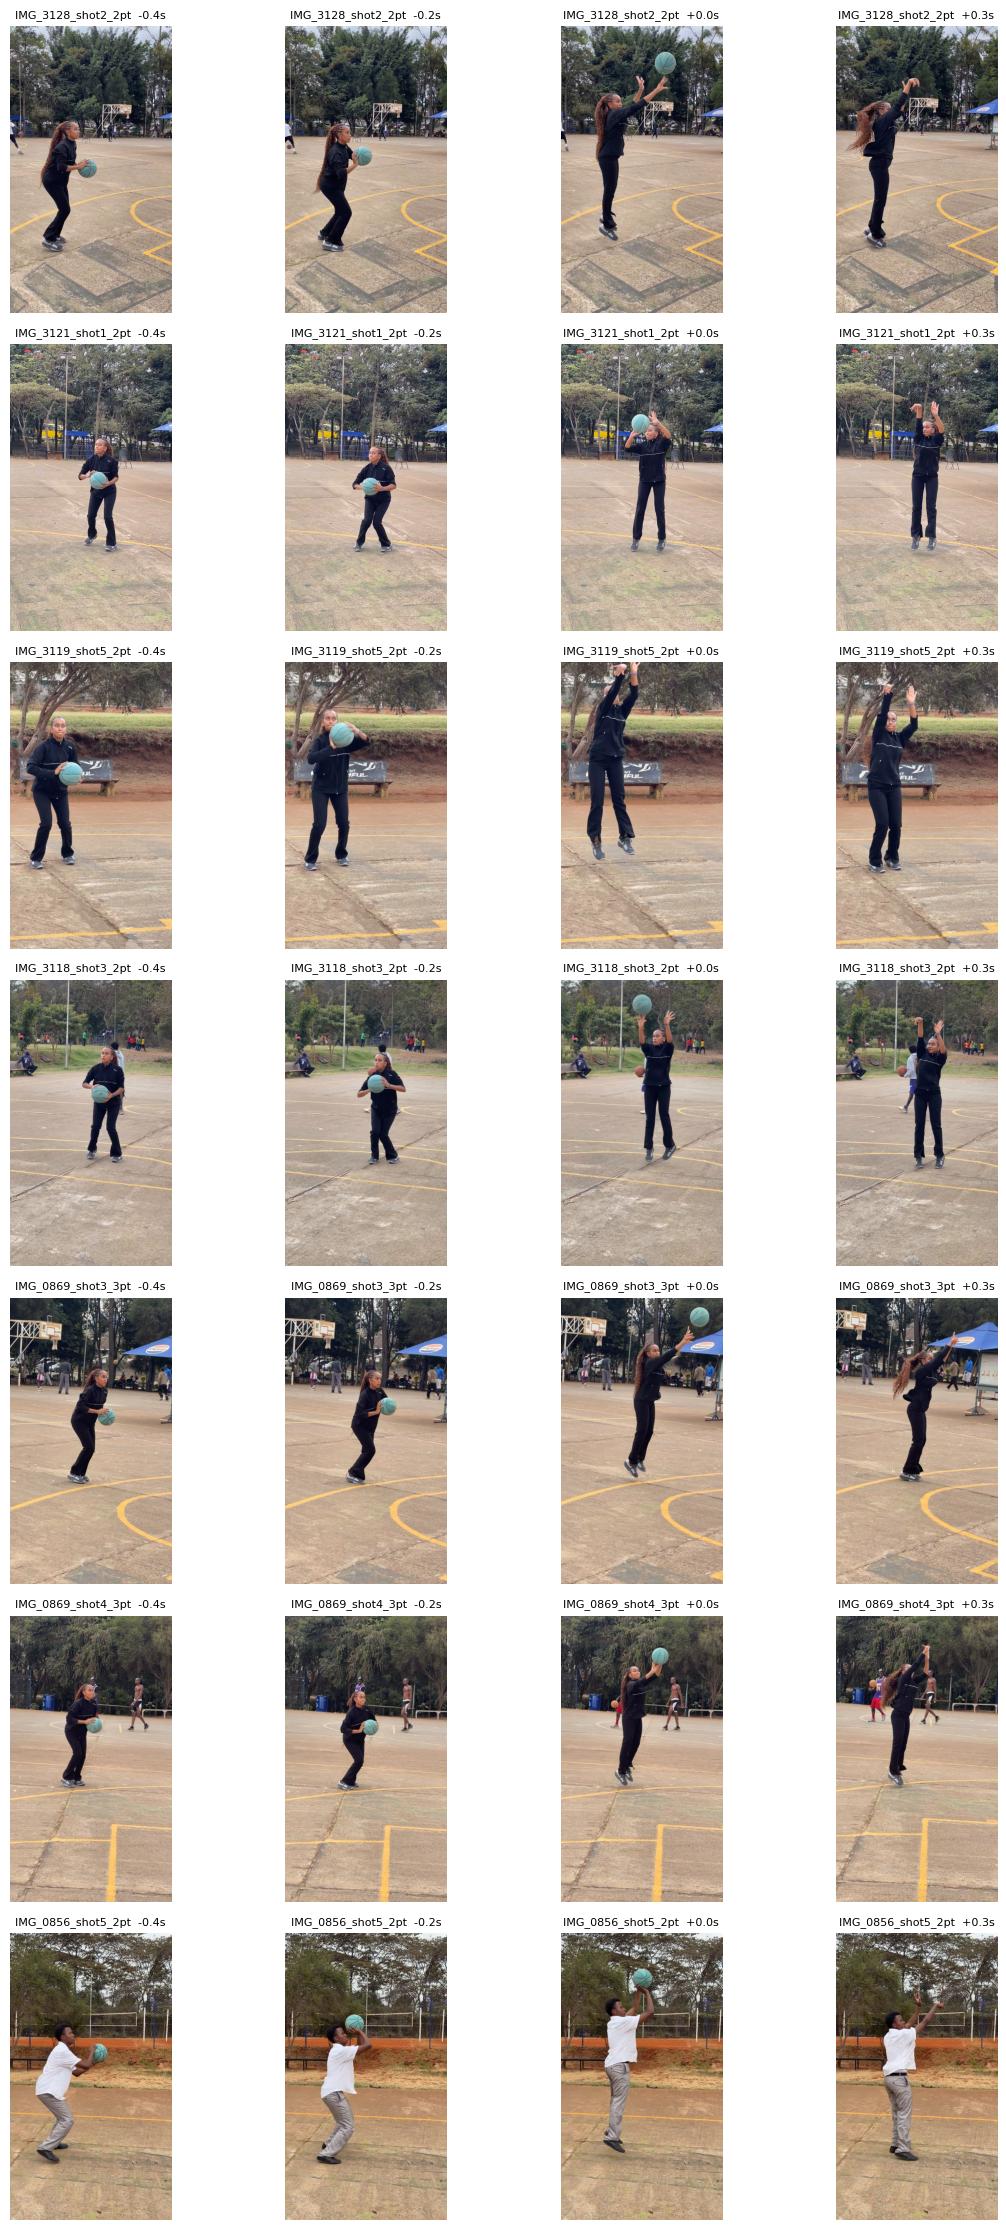

In [ ]:
# ---- CELL 11: Eyeball the 7 flagged clips at their NEW release time ----
import matplotlib.pyplot as plt
flag = df[df["edge_flag"] == 1]
offs = [-0.4, -0.2, 0, 0.3]
fig, axes = plt.subplots(len(flag), len(offs), figsize=(12, 3.2 * len(flag)))
for i, (_, r) in enumerate(flag.iterrows()):
    cap = cv2.VideoCapture(os.path.join(LOCAL_CLIPS_DIR, r["label"], r["clip"] + ".mp4"))
    for j, o in enumerate(offs):
        cap.set(cv2.CAP_PROP_POS_MSEC, (r["release_time"] + o) * 1000)
        ok, f = cap.read()
        ax = axes[i, j]; ax.axis("off")
        if ok:
            ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{r['clip'][:18]}  {o:+.1f}s", fontsize=8)
    cap.release()
plt.tight_layout(); plt.show()

In [ ]:
# ---- CELL 12: Class mix per video ----
g = df.groupby("video")["label"].agg(n="count", n_3pt=lambda x: (x == "3pt").sum())
g["n_2pt"] = g["n"] - g["n_3pt"]
print(g.sort_values("n_3pt").to_string())
print("\nVideos:", len(g), "| all-2pt:", int((g.n_3pt == 0).sum()),
      "| all-3pt:", int((g.n_2pt == 0).sum()), "| mixed:", int(((g.n_2pt > 0) & (g.n_3pt > 0)).sum()))

              n  n_3pt  n_2pt
video                        
IMG_0856.MOV  4      0      4
IMG_0857.MOV  5      0      5
IMG_0858.MOV  6      0      6
IMG_0859.MOV  5      0      5
IMG_0860.MOV  5      0      5
IMG_0861.MOV  5      0      5
IMG_0877.MOV  1      0      1
IMG_3118.MOV  5      0      5
IMG_3127.MOV  4      0      4
IMG_3128.MOV  3      0      3
IMG_3126.MOV  5      0      5
IMG_3124.MOV  5      0      5
IMG_3119.MOV  5      0      5
IMG_3121.MOV  4      0      4
IMG_0868.MOV  1      1      0
IMG_0867.MOV  2      2      0
IMG_0871.MOV  5      5      0
IMG_0870.MOV  5      5      0
IMG_0869.MOV  5      5      0
IMG_0866.MOV  5      5      0
IMG_0864.MOV  5      5      0
IMG_0865.MOV  5      5      0
IMG_0862.MOV  5      5      0
IMG_0863.MOV  5      5      0
IMG_0873.MOV  5      5      0
IMG_0872.MOV  5      5      0

Videos: 26 | all-2pt: 14 | all-3pt: 12 | mixed: 0


In [ ]:
# ---- CELL 13: Split by video (final test set + 5 grouped CV folds) ----
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
SPLIT_CSV = "/content/drive/MyDrive/CourtVision/shot_splits.csv"
rng = np.random.RandomState(SEED)

# one row per video
vid = df.groupby("video").agg(label=("label", "first"), n=("clip", "count")).reset_index()

# final test set: 2 videos per class, only from videos with >= 4 shots (so tiny videos stay in training)
eligible = vid[vid["n"] >= 4]
test_videos = []
for lab in ("2pt", "3pt"):
    pool = eligible[eligible["label"] == lab]["video"].tolist()
    test_videos += list(rng.choice(pool, size=2, replace=False))

df["split"] = np.where(df["video"].isin(test_videos), "test", "trainval")
trainval = df[df["split"] == "trainval"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

# 5 CV folds: deal videos into folds separately per class, so every fold has both classes
rng2 = np.random.RandomState(SEED)
tv_vids = trainval.groupby("video").agg(label=("label", "first")).reset_index()
fold_of = {}
for lab in ("2pt", "3pt"):
    vs = tv_vids[tv_vids["label"] == lab]["video"].tolist()
    rng2.shuffle(vs)
    for i, v in enumerate(vs):
        fold_of[v] = i % 5
trainval["fold"] = trainval["video"].map(fold_of)
folds = [(np.where(trainval["fold"] != k)[0], np.where(trainval["fold"] == k)[0]) for k in range(5)]
df["fold"] = df["clip"].map(dict(zip(trainval["clip"], trainval["fold"]))).fillna(-1).astype(int)

df[["clip", "video", "label", "split", "fold"]].to_csv(SPLIT_CSV, index=False)

print("FINAL TEST videos:", sorted(test_videos))
print(f"Test: {len(test)} shots ->", test["label"].value_counts().to_dict())
print(f"Train/val: {len(trainval)} shots ->", trainval["label"].value_counts().to_dict())
print()
for k, (tr, va) in enumerate(folds):
    tv, vv = set(trainval.loc[tr, "video"]), set(trainval.loc[va, "video"])
    assert not (tv & vv), "video leak!"
    print(f"Fold {k}: train {len(tr)} shots | val {len(va)} shots ->",
          trainval.loc[va, "label"].value_counts().to_dict(), f"| {len(vv)} videos")
print("\nNo video appears on both sides in any fold." )

FINAL TEST videos: [np.str_('IMG_0862.MOV'), np.str_('IMG_0872.MOV'), np.str_('IMG_3124.MOV'), np.str_('IMG_3126.MOV')]
Test: 20 shots -> {'2pt': 10, '3pt': 10}
Train/val: 95 shots -> {'2pt': 52, '3pt': 43}

Fold 0: train 73 shots | val 22 shots -> {'2pt': 15, '3pt': 7} | 5 videos
Fold 1: train 79 shots | val 16 shots -> {'2pt': 10, '3pt': 6} | 5 videos
Fold 2: train 78 shots | val 17 shots -> {'3pt': 10, '2pt': 7} | 4 videos
Fold 3: train 75 shots | val 20 shots -> {'2pt': 10, '3pt': 10} | 4 videos
Fold 4: train 75 shots | val 20 shots -> {'2pt': 10, '3pt': 10} | 4 videos

No video appears on both sides in any fold.


In [ ]:
# ---- CELL 14: Baseline XGBoost, 5-fold CV (grouped by video) ----
!pip install -q xgboost
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

X = trainval[FEATURE_NAMES].values
y = trainval["is_3pt"].values

params = dict(n_estimators=200, max_depth=2, learning_rate=0.05,
              subsample=0.8, colsample_bytree=0.8,
              min_child_weight=3, reg_lambda=5.0,
              eval_metric="logloss", random_state=SEED)

accs, f1s, base = [], [], []
for k, (tr, va) in enumerate(folds):
    m = XGBClassifier(**params).fit(X[tr], y[tr])
    p = m.predict(X[va])
    accs.append(accuracy_score(y[va], p)); f1s.append(f1_score(y[va], p))
    base.append(max(y[va].mean(), 1 - y[va].mean()))   # "always guess the bigger class"
    print(f"Fold {k}: acc {accs[-1]:.2f} | f1(3pt) {f1s[-1]:.2f} | always-guess baseline {base[-1]:.2f}")

print(f"\nMean acc {np.mean(accs):.3f} (+/- {np.std(accs):.3f}) | mean f1 {np.mean(f1s):.3f} | baseline {np.mean(base):.3f}")

Fold 0: acc 0.68 | f1(3pt) 0.63 | always-guess baseline 0.68
Fold 1: acc 0.75 | f1(3pt) 0.71 | always-guess baseline 0.62
Fold 2: acc 0.71 | f1(3pt) 0.71 | always-guess baseline 0.59
Fold 3: acc 0.85 | f1(3pt) 0.87 | always-guess baseline 0.50
Fold 4: acc 0.85 | f1(3pt) 0.82 | always-guess baseline 0.50

Mean acc 0.768 (+/- 0.071) | mean f1 0.749 | baseline 0.579


In [ ]:
# ---- CELL 15: Feature importance (averaged over the 5 folds) ----
from sklearn.inspection import permutation_importance

gain = np.zeros(len(FEATURE_NAMES))
perm = np.zeros(len(FEATURE_NAMES))
for k, (tr, va) in enumerate(folds):
    m = XGBClassifier(**params).fit(X[tr], y[tr])
    g = m.get_booster().get_score(importance_type="gain")
    gain_k = np.array([g.get(f"f{i}", 0.0) for i in range(len(FEATURE_NAMES))])
    gain += gain_k / (gain_k.sum() + 1e-9) - 0   # normalised so each fold counts equally
    r = permutation_importance(m, X[va], y[va], n_repeats=20, random_state=SEED, scoring="accuracy")
    perm += r.importances_mean

imp = pd.DataFrame({"feature": FEATURE_NAMES, "gain_share": gain / 5, "perm_drop": perm / 5})
imp = imp.sort_values("gain_share", ascending=False).reset_index(drop=True)
print(imp.round(3).to_string(index=False))

              feature  gain_share  perm_drop
         min_knee_pre       0.160      0.190
           knee_angle       0.104      0.009
   max_knee_ext_speed       0.103      0.014
       knee_extension       0.091      0.005
         forearm_lean       0.068      0.030
 max_wrist_rise_speed       0.065     -0.004
      jump_at_release       0.063      0.009
           trunk_lean       0.060      0.030
            jump_peak       0.054      0.017
          elbow_angle       0.048      0.001
 wrist_above_shoulder       0.047      0.001
     wrist_above_head       0.037     -0.001
            hip_angle       0.035      0.008
       shoulder_angle       0.035     -0.007
t_min_knee_to_release       0.029      0.000


In [ ]:
# ---- CELL 16: Does dropping features change CV accuracy? ----
drop6 = ["max_wrist_rise_speed", "wrist_above_head", "shoulder_angle",
         "t_min_knee_to_release", "elbow_angle", "wrist_above_shoulder"]
sets = {
    "all 15": FEATURE_NAMES,
    "drop the 6 near-zero": [f for f in FEATURE_NAMES if f not in drop6],
    "top 5 only": ["min_knee_pre", "knee_angle", "max_knee_ext_speed", "forearm_lean", "trunk_lean"],
    "min_knee_pre alone": ["min_knee_pre"],
}
for name, cols in sets.items():
    Xs = trainval[cols].values
    accs = []
    for tr, va in folds:
        m = XGBClassifier(**params).fit(Xs[tr], y[tr])
        accs.append(accuracy_score(y[va], m.predict(Xs[va])))
    print(f"{name:24s} ({len(cols):2d} feats): mean acc {np.mean(accs):.3f} (+/- {np.std(accs):.3f})")

all 15                   (15 feats): mean acc 0.768 (+/- 0.071)
drop the 6 near-zero     ( 9 feats): mean acc 0.765 (+/- 0.084)
top 5 only               ( 5 feats): mean acc 0.756 (+/- 0.084)
min_knee_pre alone       ( 1 feats): mean acc 0.703 (+/- 0.075)


In [ ]:
# ---- CELL 17: Small tuning grid (5-fold CV, grouped by video) ----
import itertools

grid = list(itertools.product([2, 3], [0.03, 0.05, 0.1], [100, 300]))   # depth, lr, trees
res = []
for depth, lr, n in grid:
    p = {**params, "max_depth": depth, "learning_rate": lr, "n_estimators": n}
    accs = []
    for tr, va in folds:
        m = XGBClassifier(**p).fit(X[tr], y[tr])
        accs.append(accuracy_score(y[va], m.predict(X[va])))
    res.append({"depth": depth, "lr": lr, "trees": n,
                "mean_acc": np.mean(accs), "std": np.std(accs)})

r = pd.DataFrame(res).sort_values("mean_acc", ascending=False).reset_index(drop=True)
print(r.round(3).to_string(index=False))

 depth   lr  trees  mean_acc   std
     2 0.10    300     0.768 0.043
     2 0.03    300     0.767 0.052
     3 0.03    300     0.767 0.052
     3 0.10    300     0.765 0.052
     2 0.05    300     0.764 0.071
     2 0.03    100     0.763 0.060
     3 0.03    100     0.763 0.060
     3 0.05    300     0.755 0.078
     2 0.05    100     0.754 0.061
     3 0.05    100     0.754 0.061
     3 0.10    100     0.735 0.062
     2 0.10    100     0.725 0.063


In [ ]:
# ---- CELL 18: FINAL test evaluation (run once) + save model ----
import json
from sklearn.metrics import confusion_matrix, classification_report

Xt = test[FEATURE_NAMES].values
yt = test["is_3pt"].values

final = XGBClassifier(**params).fit(X, y)          # all 95 train/val shots
pred = final.predict(Xt)

print(f"TEST accuracy: {accuracy_score(yt, pred):.3f}  ({int((pred == yt).sum())}/{len(yt)} shots)")
print("\nConfusion matrix (rows = true, cols = predicted; order 2pt, 3pt):")
print(confusion_matrix(yt, pred, labels=[0, 1]))
print("\n", classification_report(yt, pred, target_names=["2pt", "3pt"], digits=2))

out = test[["clip", "video", "label"]].copy()
out["pred"] = np.where(pred == 1, "3pt", "2pt")
out["correct"] = (out["pred"] == out["label"]).astype(int)
print("Per-video accuracy:")
print(out.groupby("video")["correct"].agg(["mean", "count"]).round(2).to_string())
print("\nWrong shots:")
w = out[out["correct"] == 0]
print(w[["clip", "label", "pred"]].to_string(index=False) if len(w) else "none")

MODEL_DIR = "/content/drive/MyDrive/CourtVision/models"
os.makedirs(MODEL_DIR, exist_ok=True)
final.save_model(f"{MODEL_DIR}/xgb_shot_classifier.json")
with open(f"{MODEL_DIR}/xgb_feature_order.json", "w") as f:
    json.dump(FEATURE_NAMES, f)
print("\nSaved model + feature order ->", MODEL_DIR)

TEST accuracy: 0.900  (18/20 shots)

Confusion matrix (rows = true, cols = predicted; order 2pt, 3pt):
[[9 1]
 [1 9]]

               precision    recall  f1-score   support

         2pt       0.90      0.90      0.90        10
         3pt       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20

Per-video accuracy:
              mean  count
video                    
IMG_0862.MOV   1.0      5
IMG_0872.MOV   0.8      5
IMG_3124.MOV   1.0      5
IMG_3126.MOV   0.8      5

Wrong shots:
              clip label pred
IMG_3126_shot2_2pt   2pt  3pt
IMG_0872_shot3_3pt   3pt  2pt

Saved model + feature order -> /content/drive/MyDrive/CourtVision/models


In [ ]:
# ---- CELL 19: Pose on 4 FULL raw videos (resumable) ----
TEST_VIDEOS = ["IMG_0859.MOV", "IMG_0871.MOV", "IMG_0869.MOV", "IMG_3119.MOV"]
RAW_DIR = "/content/drive/MyDrive/CourtVision/raw_shots_footage"     # EDIT if yours differs
LOCAL_RAW = "/content/raw_small"
FULL_LM_DIR = os.path.join(LANDMARKS_DIR, "full")
os.makedirs(LOCAL_RAW, exist_ok=True)
os.makedirs(FULL_LM_DIR, exist_ok=True)

for v in TEST_VIDEOS:
    stem = os.path.splitext(v)[0]
    out_npz = os.path.join(FULL_LM_DIR, stem + ".npz")
    if os.path.exists(out_npz):
        print(stem, "already done")
        continue
    small = os.path.join(LOCAL_RAW, stem + ".mp4")
    if not os.path.exists(small):
        src_local = f"/content/{v}"
        shutil.copy2(os.path.join(RAW_DIR, v), src_local)
        os.system(f'ffmpeg -y -loglevel error -i "{src_local}" -vf scale=640:-2 -r 30 '
                  f'-c:v libx264 -preset ultrafast -an "{small}"')
        os.remove(src_local)
    t0 = time.time()
    lms, fps = extract_landmarks(small)
    np.savez_compressed(out_npz, lms=lms, fps=fps)
    found = np.mean(~np.isnan(lms[:, R_WRIST, 0]))
    print(f"{stem}: {len(lms)} frames ({len(lms)/fps:.0f}s), pose found in {found:.0%}, {time.time()-t0:.0f}s", flush=True)

IMG_0859: 590 frames (20s), pose found in 100%, 25s
IMG_0871: 825 frames (28s), pose found in 95%, 35s
IMG_0869: 721 frames (24s), pose found in 94%, 28s
IMG_3119: 756 frames (25s), pose found in 97%, 31s


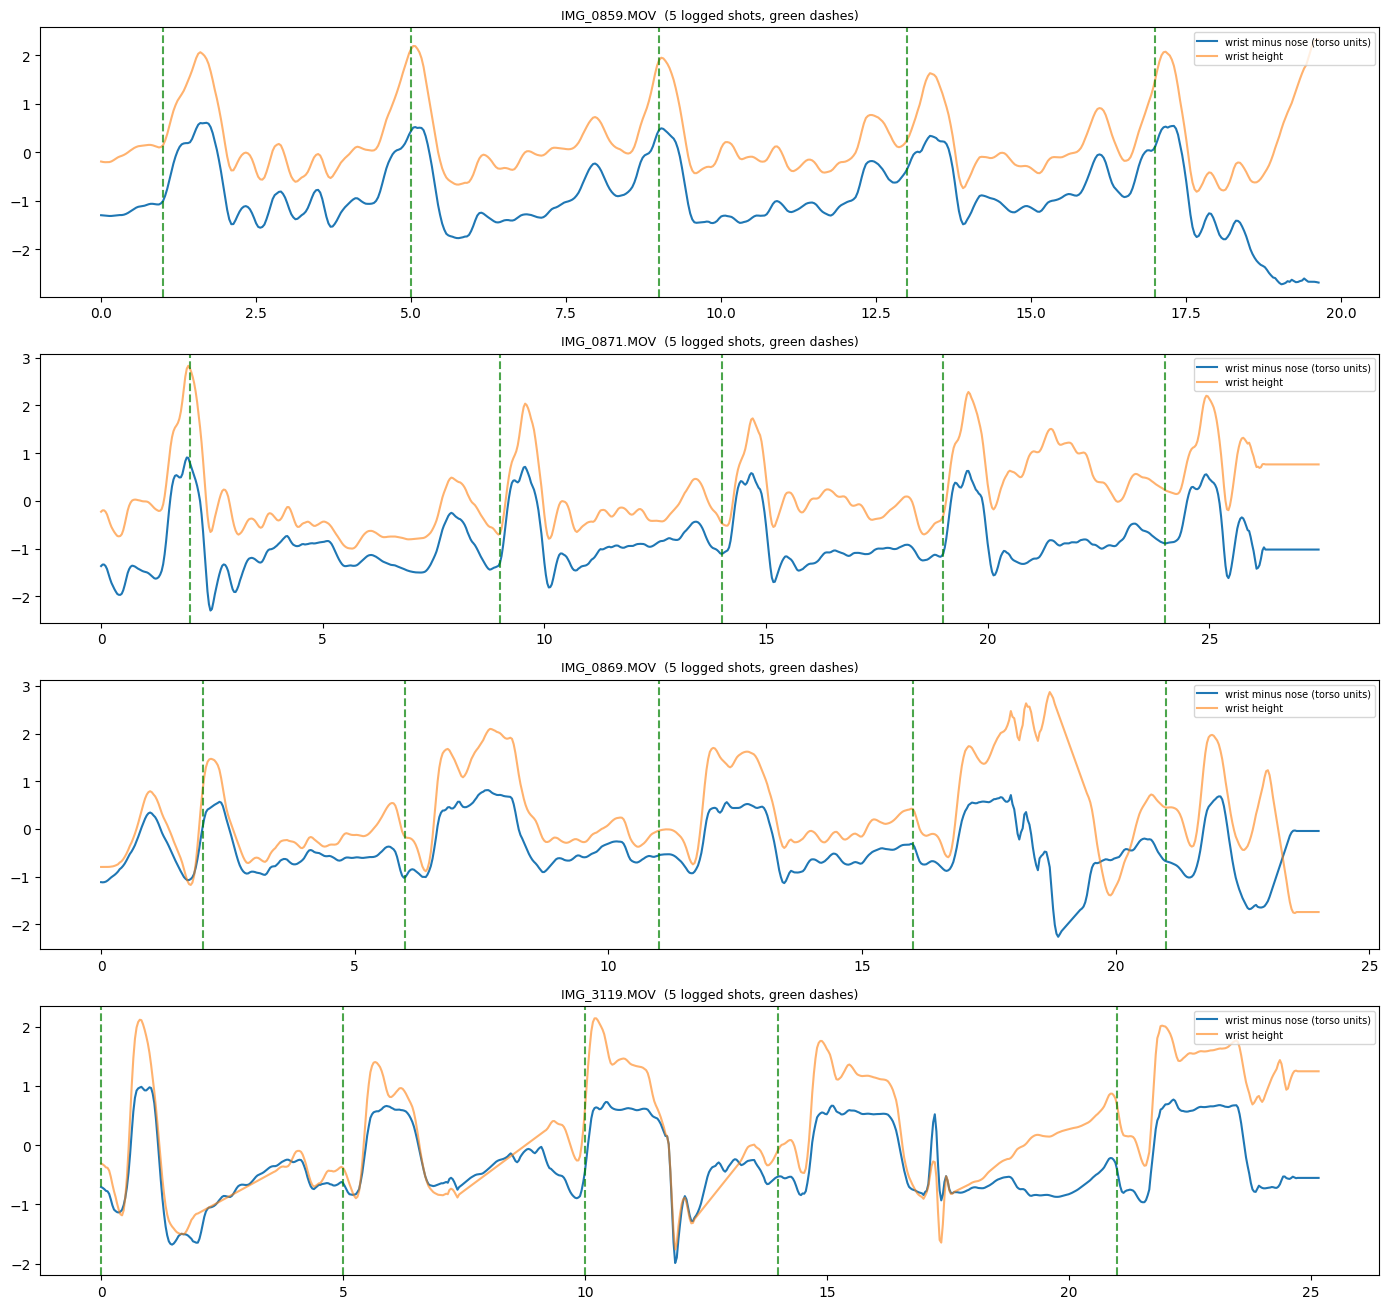

In [ ]:
# ---- CELL 20: Wrist signal over the full video, your logged shots in green ----
import matplotlib.pyplot as plt

wb = openpyxl.load_workbook(SHOT_LOG_PATH, data_only=True)
ws = wb.active
logged = {}
for video, n, ts, lab in ws.iter_rows(min_row=3, max_row=ws.max_row, max_col=4, values_only=True):
    if video and isinstance(ts, (int, float)):
        logged.setdefault(str(video).strip(), []).append(float(ts))

fig, axes = plt.subplots(len(TEST_VIDEOS), 1, figsize=(14, 3.3 * len(TEST_VIDEOS)))
for ax, v in zip(axes, TEST_VIDEOS):
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"]); T = len(lms)
    idx = [NOSE, R_SHOULDER, R_WRIST, R_HIP]
    xy = lms[:, idx, :2].copy()
    xy[lms[:, idx, 2] < VIS_THRESHOLD] = np.nan
    pts = smooth(interp_nans(xy.reshape(T, -1))).reshape(T, 4, 2)
    pts[:, :, 1] *= -1
    nose, sh, wr, hip = [pts[:, i] for i in range(4)]
    torso = np.median(np.linalg.norm(sh - hip, axis=1))
    t = np.arange(T) / fps
    ax.plot(t, (wr[:, 1] - nose[:, 1]) / torso, label="wrist minus nose (torso units)")
    ax.plot(t, (wr[:, 1] - np.median(wr[:, 1])) / torso, label="wrist height", alpha=0.6)
    for ts in logged.get(v, []):
        ax.axvline(ts, color="g", ls="--", alpha=0.7)
    ax.set_title(f"{v}  ({len(logged.get(v, []))} logged shots, green dashes)", fontsize=9)
    ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# ---- CELL 21: Automatic shot finder (no timestamps) + check on the 4 dev videos ----
from scipy.signal import find_peaks

MIN_GAP_S  = 2.5   # shots at least this far apart
MIN_PROM   = 0.8   # peak must stand this far above its surroundings (torso units)
MIN_HEIGHT = 0.0   # wrist must reach nose level or higher

def find_shots(lms, fps):
    T = len(lms)
    idx = [NOSE, R_SHOULDER, R_WRIST, R_HIP]
    xy = lms[:, idx, :2].copy()
    xy[lms[:, idx, 2] < VIS_THRESHOLD] = np.nan
    pts = smooth(interp_nans(xy.reshape(T, -1))).reshape(T, 4, 2)
    pts[:, :, 1] *= -1
    nose, sh, wr, hip = [pts[:, i] for i in range(4)]
    torso = np.median(np.linalg.norm(sh - hip, axis=1)) + 1e-9
    sig = (wr[:, 1] - nose[:, 1]) / torso
    pk, _ = find_peaks(sig, height=MIN_HEIGHT, prominence=MIN_PROM, distance=int(MIN_GAP_S * fps))
    out = []
    for p in pk:
        a, b = max(0, p - int(0.6 * fps)), min(T, p + int(0.6 * fps) + 1)
        k = a + int(np.argmax(wr[a:b, 1]))               # same wrist-peak rule as training
        out.append({"peak_t": p / fps, "release_t": max(0.0, k / fps - PEAK_TO_RELEASE)})
    return out

# fps check: training clips vs these full videos
print("fps of a training clip:", float(np.load(os.path.join(LANDMARKS_DIR, shots[0]["clip"] + ".npz"))["fps"]))

for v in TEST_VIDEOS:
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"])
    found, lg = find_shots(lms, fps), sorted(logged[v])
    missed = [t for t in lg if not any(0 <= s["peak_t"] - t <= 1.6 for s in found)]
    extra  = [round(s["peak_t"], 1) for s in found if not any(0 <= s["peak_t"] - t <= 1.6 for t in lg)]
    print(f"\n{v}: found {len(found)} | logged {len(lg)} | fps {fps:.0f} | missed {missed} | extra peaks at {extra}")
    for s in found:
        prior = [t for t in lg if t <= s["peak_t"] + 0.2]
        near = prior[-1] if prior else np.nan
        a = max(0, int(round((s["release_t"] - 2.0) * fps)))
        b = min(len(lms), int(round((s["release_t"] + 2.0) * fps)))
        feats, cov = compute_features(lms[a:b], fps, s["release_t"] - a / fps)   # same 4s window as training
        print(f"  peak {s['peak_t']:5.1f}s | release {s['release_t']:5.2f}s | logged {near:4.0f}s "
              f"(peak-logged {s['peak_t'] - near:+.1f}s) | coverage {cov:.2f}")

fps of a training clip: 30.0

IMG_0859.MOV: found 5 | logged 5 | fps 30 | missed [] | extra peaks at []
  peak   1.7s | release  1.50s | logged    1s (peak-logged +0.7s) | coverage 1.00
  peak   5.1s | release  4.93s | logged    5s (peak-logged +0.1s) | coverage 1.00
  peak   9.0s | release  8.93s | logged    9s (peak-logged +0.0s) | coverage 1.00
  peak  13.4s | release 13.27s | logged   13s (peak-logged +0.4s) | coverage 1.00
  peak  17.3s | release 17.07s | logged   17s (peak-logged +0.3s) | coverage 1.00

IMG_0871.MOV: found 5 | logged 5 | fps 30 | missed [2.0] | extra peaks at [np.float64(1.9)]
  peak   1.9s | release  1.87s | logged    2s (peak-logged -0.1s) | coverage 1.00
  peak   9.6s | release  9.47s | logged    9s (peak-logged +0.6s) | coverage 1.00
  peak  14.7s | release 14.60s | logged   14s (peak-logged +0.7s) | coverage 1.00
  peak  19.6s | release 19.47s | logged   19s (peak-logged +0.6s) | coverage 1.00
  peak  24.9s | release 24.83s | logged   24s (peak-logged +0.9s)

In [ ]:
# ---- CELL 22: Finder vs training anchors (dev videos only; not an accuracy test) ----
ts_map = {}
for video, n, ts, lab in ws.iter_rows(min_row=3, max_row=ws.max_row, max_col=4, values_only=True):
    if video and isinstance(ts, (int, float)):
        ts_map[(str(video).strip(), int(n))] = float(ts)

CHK = ["min_knee_pre", "knee_angle", "forearm_lean", "max_knee_ext_speed"]
for v in TEST_VIDEOS:
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"])
    tr = df[df["video"] == v].copy()
    tr["abs_rel"] = [max(0.0, ts_map[(v, int(n))] - 2.0) + r
                     for n, r in zip(tr["shot_number"], tr["release_time"])]
    print(f"\n{v}")
    for s in find_shots(lms, fps):
        j = (tr["abs_rel"] - s["release_t"]).abs().idxmin()
        row = tr.loc[j]
        a = max(0, int(round((s["release_t"] - 2.0) * fps)))
        b = min(len(lms), int(round((s["release_t"] + 2.0) * fps)))
        f, _ = compute_features(lms[a:b], fps, s["release_t"] - a / fps)
        diffs = " | ".join(f"{c} {f[c] - row[c]:+.0f}" for c in CHK)
        print(f"  finder {s['release_t']:5.2f}s vs training {row['abs_rel']:5.2f}s "
              f"(shot {int(row['shot_number'])}, diff {s['release_t'] - row['abs_rel']:+.2f}s) | {diffs}")


IMG_0859.MOV
  finder  1.50s vs training  1.43s (shot 1, diff +0.07s) | min_knee_pre +0 | knee_angle +1 | forearm_lean +11 | max_knee_ext_speed -35
  finder  4.93s vs training  4.87s (shot 2, diff +0.06s) | min_knee_pre -1 | knee_angle +1 | forearm_lean +11 | max_knee_ext_speed -60
  finder  8.93s vs training  8.90s (shot 3, diff +0.03s) | min_knee_pre +2 | knee_angle -4 | forearm_lean -7 | max_knee_ext_speed -33
  finder 13.27s vs training 13.28s (shot 4, diff -0.01s) | min_knee_pre +0 | knee_angle -4 | forearm_lean -17 | max_knee_ext_speed -83
  finder 17.07s vs training 17.03s (shot 5, diff +0.04s) | min_knee_pre +2 | knee_angle -1 | forearm_lean -0 | max_knee_ext_speed -45

IMG_0871.MOV
  finder  1.87s vs training  1.82s (shot 1, diff +0.05s) | min_knee_pre +1 | knee_angle -2 | forearm_lean -3 | max_knee_ext_speed -15
  finder  9.47s vs training  9.42s (shot 2, diff +0.05s) | min_knee_pre +2 | knee_angle -0 | forearm_lean -92 | max_knee_ext_speed -20
  finder 14.60s vs training 14

In [ ]:
# ---- CELL 23: Pose on the other train/val videos (test videos are excluded on purpose) ----
dev_videos = sorted(df.loc[df["split"] == "trainval", "video"].unique())
assert not (set(dev_videos) & set(test_videos)), "a test video leaked into the dev list!"
print(len(dev_videos), "train/val videos;", len(test_videos), "test videos untouched")

for v in dev_videos:
    stem = os.path.splitext(v)[0]
    out_npz = os.path.join(FULL_LM_DIR, stem + ".npz")
    if os.path.exists(out_npz):
        continue
    small = os.path.join(LOCAL_RAW, stem + ".mp4")
    if not os.path.exists(small):
        src_local = f"/content/{v}"
        shutil.copy2(os.path.join(RAW_DIR, v), src_local)
        os.system(f'ffmpeg -y -loglevel error -i "{src_local}" -vf scale=640:-2 -r 30 '
                  f'-c:v libx264 -preset ultrafast -an "{small}"')
        os.remove(src_local)
    t0 = time.time()
    lms, fps = extract_landmarks(small)
    np.savez_compressed(out_npz, lms=lms, fps=fps)
    print(f"{stem}: {len(lms)/fps:.0f}s, pose found {np.mean(~np.isnan(lms[:, R_WRIST, 0])):.0%}, {time.time()-t0:.0f}s", flush=True)
print("done")


22 train/val videos; 4 test videos untouched
IMG_0856: 26s, pose found 96%, 37s
IMG_0857: 26s, pose found 96%, 31s
IMG_0858: 35s, pose found 91%, 41s
IMG_0860: 21s, pose found 100%, 32s
IMG_0861: 22s, pose found 97%, 28s
IMG_0863: 26s, pose found 97%, 32s
IMG_0864: 24s, pose found 100%, 29s
IMG_0865: 25s, pose found 100%, 31s
IMG_0866: 24s, pose found 100%, 30s
IMG_0867: 26s, pose found 87%, 31s
IMG_0868: 16s, pose found 92%, 21s
IMG_0870: 30s, pose found 95%, 37s
IMG_0873: 28s, pose found 100%, 35s
IMG_0877: 10s, pose found 70%, 18s
IMG_3118: 26s, pose found 97%, 32s
IMG_3121: 27s, pose found 96%, 32s
IMG_3127: 19s, pose found 94%, 23s
IMG_3128: 14s, pose found 95%, 18s
done


In [ ]:
# ---- CELL 24: Tune the release rule on all 22 train/val videos ----
def wrist_and_signal(lms):
    T = len(lms)
    idx = [NOSE, R_SHOULDER, R_WRIST, R_HIP]
    xy = lms[:, idx, :2].copy()
    xy[lms[:, idx, 2] < VIS_THRESHOLD] = np.nan
    pts = smooth(interp_nans(xy.reshape(T, -1))).reshape(T, 4, 2)
    pts[:, :, 1] *= -1
    nose, sh, wr, hip = [pts[:, i] for i in range(4)]
    torso = np.median(np.linalg.norm(sh - hip, axis=1)) + 1e-9
    return wr[:, 1], (wr[:, 1] - nose[:, 1]) / torso

def release_rule(wy, p, fps, frac, lag):
    """First moment the wrist reaches `frac` of its rise, then step back `lag` seconds."""
    T = len(wy)
    lo, hi = max(0, p - int(1.5 * fps)), min(T, p + int(0.3 * fps) + 1)
    base = wy[lo:p + 1].min()
    top = wy[max(0, p - int(0.9 * fps)):hi].max()
    ok = np.where(wy[lo:hi] >= base + frac * (top - base))[0]
    k = lo + (ok[0] if len(ok) else p - lo)
    return max(0.0, k / fps - lag)

df["abs_rel"] = [max(0.0, ts_map[(v, int(n))] - 2.0) + r
                 for v, n, r in zip(df["video"], df["shot_number"], df["release_time"])]

cases, missed_n, extra_n = [], 0, 0
for v in dev_videos:
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"])
    wy, sig = wrist_and_signal(lms)
    pk, _ = find_peaks(sig, height=MIN_HEIGHT, prominence=MIN_PROM, distance=int(MIN_GAP_S * fps))
    anchors = df.loc[(df["video"] == v), "abs_rel"].values
    used = set()
    for p in pk:
        j = int(np.argmin(np.abs(anchors - p / fps)))
        if abs(anchors[j] - p / fps) < 2.0 and j not in used:
            used.add(j); cases.append((v, wy, p, fps, anchors[j]))
        else:
            extra_n += 1
    missed_n += len(anchors) - len(used)
print(f"Matched {len(cases)} shots | anchors with no peak found: {missed_n} | peaks with no anchor: {extra_n}")

rows = []
for frac in (0.8, 0.9, 0.95, 1.0):
    for lag in (0.0, 0.1, 0.2):
        diff = np.array([release_rule(wy, p, fps, frac, lag) - a for (_, wy, p, fps, a) in cases])
        rows.append({"frac": frac, "lag": lag, "median_diff": np.median(diff),
                     "median_abs": np.median(np.abs(diff)),
                     "within_0.15s": np.mean(np.abs(diff) <= 0.15),
                     "within_0.30s": np.mean(np.abs(diff) <= 0.30),
                     "worst": np.abs(diff).max()})
res = pd.DataFrame(rows).sort_values(["within_0.15s", "median_abs"], ascending=[False, True])
print(res.round(2).to_string(index=False))

best = res.iloc[0]
print(f"\nBest rule: frac={best.frac}, lag={best.lag}. Shots off by more than 0.3s:")
for (v, wy, p, fps, a) in cases:
    dd = release_rule(wy, p, fps, best.frac, best.lag) - a
    if abs(dd) > 0.3:
        print(f"  {v}: anchor {a:.2f}s, finder {a + dd:.2f}s ({dd:+.2f}s)")

Matched 92 shots | anchors with no peak found: 3 | peaks with no anchor: 4
 frac  lag  median_diff  median_abs  within_0.15s  within_0.30s  worst
 0.80  0.0         0.02        0.04          0.95          0.96   2.00
 0.95  0.1        -0.01        0.03          0.92          0.93   1.46
 0.90  0.0         0.07        0.07          0.92          0.93   1.46
 0.95  0.0         0.09        0.10          0.92          0.93   1.42
 0.90  0.1        -0.03        0.05          0.91          0.93   1.56
 0.80  0.1        -0.08        0.08          0.89          0.96   2.10
 1.00  0.2        -0.06        0.07          0.86          0.92   1.53
 1.00  0.1         0.04        0.05          0.85          0.91   1.45
 0.95  0.2        -0.11        0.11          0.79          0.92   1.56
 1.00  0.0         0.14        0.14          0.59          0.87   1.55
 0.90  0.2        -0.13        0.15          0.54          0.92   1.66
 0.80  0.2        -0.18        0.18          0.23          0.93   2.20

B

In [ ]:
# ---- CELL 25: FROZEN finder, end-to-end on the 4 held-out test videos (RUN ONCE) ----
FROZEN_FRAC, FROZEN_LAG = 0.8, 0.0

def find_shots_final(lms, fps):
    wy, sig = wrist_and_signal(lms)
    pk, _ = find_peaks(sig, height=MIN_HEIGHT, prominence=MIN_PROM, distance=int(MIN_GAP_S * fps))
    return [{"peak_t": p / fps, "release_t": release_rule(wy, p, fps, FROZEN_FRAC, FROZEN_LAG)} for p in pk]

# pose on the 4 test videos (same steps as Cell 23)
for v in test_videos:
    stem = os.path.splitext(v)[0]
    out_npz = os.path.join(FULL_LM_DIR, stem + ".npz")
    if os.path.exists(out_npz):
        continue
    small = os.path.join(LOCAL_RAW, stem + ".mp4")
    if not os.path.exists(small):
        src_local = f"/content/{v}"
        shutil.copy2(os.path.join(RAW_DIR, v), src_local)
        os.system(f'ffmpeg -y -loglevel error -i "{src_local}" -vf scale=640:-2 -r 30 '
                  f'-c:v libx264 -preset ultrafast -an "{small}"')
        os.remove(src_local)
    lms, fps = extract_landmarks(small)
    np.savez_compressed(out_npz, lms=lms, fps=fps)
    print("pose done:", stem, flush=True)

# end-to-end
res = []
for v in sorted(test_videos):
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"])
    true_lab = df.loc[df["video"] == v, "label"].iloc[0]
    anchors = df.loc[df["video"] == v, "abs_rel"].values
    found = find_shots_final(lms, fps)
    print(f"\n{v} (true: {true_lab}) | found {len(found)} shots | logged {len(anchors)}")
    for s in found:
        a = max(0, int(round((s["release_t"] - 2.0) * fps)))
        b = min(len(lms), int(round((s["release_t"] + 2.0) * fps)))
        f, cov = compute_features(lms[a:b], fps, s["release_t"] - a / fps)
        if np.isnan(list(f.values())).any():
            print(f"  release {s['release_t']:5.2f}s | no features (coverage {cov:.2f})")
            continue
        p3 = final.predict_proba(np.array([[f[k] for k in FEATURE_NAMES]]))[0, 1]
        pred = "3pt" if p3 >= 0.5 else "2pt"
        real = bool(np.any(np.abs(anchors - s["release_t"]) < 2.0))
        res.append({"video": v, "true": true_lab, "pred": pred, "real_shot": real})
        print(f"  release {s['release_t']:5.2f}s | P(3pt) {p3:.2f} -> {pred} "
              f"{'OK' if pred == true_lab else 'WRONG'} | matches a logged shot: {real} | coverage {cov:.2f}")

r = pd.DataFrame(res)
rr = r[r["real_shot"]]
print(f"\nEND-TO-END accuracy on real shots: {(rr['pred'] == rr['true']).mean():.3f} ({int((rr['pred'] == rr['true']).sum())}/{len(rr)})")
print("Invented shots (no logged match):", int((~r['real_shot']).sum()))
print("For comparison, logged-timestamp test accuracy was 18/20 = 0.900")

pose done: IMG_3126
pose done: IMG_3124
pose done: IMG_0862
pose done: IMG_0872

IMG_0862.MOV (true: 3pt) | found 5 shots | logged 5
  release  3.67s | P(3pt) 0.42 -> 2pt WRONG | matches a logged shot: True | coverage 1.00
  release  9.10s | P(3pt) 0.80 -> 3pt OK | matches a logged shot: True | coverage 1.00
  release 15.57s | P(3pt) 0.77 -> 3pt OK | matches a logged shot: True | coverage 1.00
  release 20.13s | P(3pt) 0.89 -> 3pt OK | matches a logged shot: True | coverage 1.00
  release 24.70s | P(3pt) 0.90 -> 3pt OK | matches a logged shot: True | coverage 1.00

IMG_0872.MOV (true: 3pt) | found 5 shots | logged 5
  release  3.03s | P(3pt) 0.95 -> 3pt OK | matches a logged shot: True | coverage 1.00
  release 11.33s | P(3pt) 0.45 -> 2pt WRONG | matches a logged shot: True | coverage 1.00
  release 21.20s | P(3pt) 0.38 -> 2pt WRONG | matches a logged shot: True | coverage 1.00
  release 26.37s | P(3pt) 0.61 -> 3pt OK | matches a logged shot: True | coverage 0.97
  release 32.83s | P(3

In [ ]:
# ---- CELL 26: Clip features vs full-video features (train/val videos only) ----
rows = []
for v in dev_videos:
    d = np.load(os.path.join(FULL_LM_DIR, os.path.splitext(v)[0] + ".npz"))
    lms, fps = d["lms"], float(d["fps"])
    sub = df[df["video"] == v]
    anchors = sub["abs_rel"].values
    used = set()
    for s in find_shots_final(lms, fps):
        j = int(np.argmin(np.abs(anchors - s["release_t"])))
        if abs(anchors[j] - s["release_t"]) < 1.0 and j not in used:
            used.add(j)
            a = max(0, int(round((s["release_t"] - 2.0) * fps)))
            b = min(len(lms), int(round((s["release_t"] + 2.0) * fps)))
            f, _ = compute_features(lms[a:b], fps, s["release_t"] - a / fps)
            rows.append({"clip": sub.iloc[j]["clip"], **f})
fin = pd.DataFrame(rows).dropna(subset=FEATURE_NAMES).set_index("clip")
tvi = trainval.set_index("clip")
print(len(fin), "matched train/val shots")

acc_c, acc_f = [], []
for k, (tr, va) in enumerate(folds):
    m = XGBClassifier(**params).fit(X[tr], y[tr])
    vc = [c for c in trainval.loc[va, "clip"] if c in fin.index]
    yv = tvi.loc[vc, "is_3pt"].values
    ac = accuracy_score(yv, m.predict(tvi.loc[vc, FEATURE_NAMES].values))
    af = accuracy_score(yv, m.predict(fin.loc[vc, FEATURE_NAMES].values))
    acc_c.append(ac); acc_f.append(af)
    print(f"Fold {k}: {len(vc)} shots | cut-clip features {ac:.2f} | full-video features {af:.2f}")
print(f"\nMean: cut-clip {np.mean(acc_c):.3f} | full-video {np.mean(acc_f):.3f}")

common = fin.index
d = (fin.loc[common, FEATURE_NAMES] - tvi.loc[common, FEATURE_NAMES]).mean()
gap = (tvi.loc[common].groupby("label")[FEATURE_NAMES].mean().diff().iloc[-1]).abs()
print("\nFeature shift (full-video minus cut-clip) vs the 2pt/3pt gap:")
print(pd.DataFrame({"shift": d, "class_gap": gap, "shift/gap": d.abs() / (gap + 1e-9)})
        .round(2).sort_values("shift/gap", ascending=False).to_string())

90 matched train/val shots
Fold 0: 22 shots | cut-clip features 0.68 | full-video features 0.68
Fold 1: 13 shots | cut-clip features 0.85 | full-video features 0.69
Fold 2: 16 shots | cut-clip features 0.69 | full-video features 0.69
Fold 3: 19 shots | cut-clip features 0.84 | full-video features 0.79
Fold 4: 20 shots | cut-clip features 0.85 | full-video features 0.80

Mean: cut-clip 0.782 | full-video 0.730

Feature shift (full-video minus cut-clip) vs the 2pt/3pt gap:
                       shift  class_gap  shift/gap
wrist_above_head       -0.03       0.00     469.28
jump_at_release        -0.05       0.00      20.63
shoulder_angle         -1.20       0.53       2.28
elbow_angle            -3.06       1.58       1.94
max_wrist_rise_speed   -0.73       0.57       1.28
wrist_above_shoulder   -0.03       0.02       1.26
forearm_lean           -7.26      12.19       0.60
max_knee_ext_speed    -47.10     111.00       0.42
jump_peak              -0.02       0.07       0.28
t_min_knee_to_